# AI-READI in the Cloud: a hands-on tour of the synthetic T2DM dataset

**Dataset:** ADVANCE Center Synthetic AI-READI Dataset for T2DM Research (read-only S3 bucket)
**Runs on:** any Jupyter environment with network access to S3. A GPU is optional.

**What we will do**

1. Meet AI-READI and its synthetic twin
2. Connect to the data in the cloud
3. Tour every data type: retinal photos, OCT, ECG, wearables and CGM, clinical records
4. Look for relationships across data types
5. Play a game: *which device took this scan?* Humans vs a small neural network
6. Leave with research questions worth a grant

## 1. What is AI-READI?

**AI-READI** (Artificial Intelligence Ready and Exploratory Atlas for Diabetes Insights) is one of the flagship
data generation projects of the NIH Common Fund **Bridge2AI** program. Its aim is a dataset built for AI from day
one, to study **salutogenesis** in type 2 diabetes: what separates people who move toward health from those who
do not.

**Who is in it.** The study targets 4,000 adults aged 40 and older, recruited at UAB, UCSD and UW, and balanced by
design across three factors:

| Factor | Groups |
|---|---|
| Diabetes severity | no diabetes; prediabetes or lifestyle-controlled; oral medication or non-insulin injectables; insulin |
| Race and ethnicity | Asian, Black, Hispanic, White |
| Sex | female, male |

**What is measured.** Each participant contributes many data types, each stored in a community standard:

| Data type | Devices | Standard |
|---|---|---|
| Retinal photography (color, infrared, autofluorescence) | Optomed Aurora, iCare Eidon, Topcon Maestro2, Topcon Triton, Heidelberg Spectralis, Zeiss Cirrus | DICOM |
| Retinal OCT and OCT angiography | Heidelberg Spectralis, Topcon Maestro2, Topcon Triton, Zeiss Cirrus | DICOM |
| 12-lead ECG | Philips PageWriter TC30 | WFDB |
| Continuous glucose monitoring (10 days) | Dexcom G6 | Open mHealth JSON |
| Physical activity, heart rate, sleep, stress | Garmin Vivosmart 5 | Open mHealth JSON |
| Home environment (particulates, VOCs, light) | LeeLab Anura sensor | CSV |
| Clinical data, labs, surveys, cognition | study visit | OMOP CDM |

**Releases.** v1.0.0 (May 2024, 204 pilot participants), v2.0.0 (Nov 2024, 863 added), v3.0.0 (Nov 2025, 1,213
added, about 2,280 in total and 3.82 TB). The real data is distributed through **FAIRhub** under a data license
agreement; a few sensitive fields need Data Access Committee approval.

Sources: [docs.aireadi.org](https://docs.aireadi.org/), [changelog](https://docs.aireadi.org/docs/3/changelog),
[protocol paper, BMJ Open 2025](https://pmc.ncbi.nlm.nih.gov/articles/PMC11800295/),
[Nature Metabolism 2024](https://doi.org/10.1038/s42255-024-01165-x), [aireadi.org](https://aireadi.org/).

### 1.1 Why a synthetic version?

The real release needs a data license, and some fields need committee approval. To let people explore, teach and
prototype first, the **ADVANCE Center** at Vanderbilt University Medical Center built a synthetic companion from
AI-READI v3.0.0, published on the AWS Marketplace as *ADVANCE Center Synthetic AI-READI Dataset for T2DM Research*
and archived on [Zenodo](https://doi.org/10.5281/zenodo.22944362).

How it was made ([code](https://github.com/nicholas-j-jackson/ai_readi_synth)):

* **Images:** a latent diffusion model trained on 256 x 256 images and conditioned on each image's
  device, anatomical region, laterality (left or right eye) and disease labels.
* **Tabular data:** a reinforcement-learning based generator that produces whole participant records.
* The three modules (fundus photos, OCT, tabular) were **generated independently**.

That last point shapes what we can and cannot ask:

| Module | Records | Linked to |
|---|---|---|
| Retinal photography | 93,856 images | its own AMD, glaucoma and diabetic retinopathy labels |
| Retinal OCT | 56,512 B-scans | its own AMD, glaucoma and diabetic retinopathy labels |
| Tabular cohort | 10,518 synthetic participants | clinical labs, conditions, ECG measurements, wearable and CGM summaries, all sharing one `participant_id` |

Images are **not** linked to the tabular participants. A `participant_id` of 42 in the OCT folder and 42 in the ECG
folder are unrelated synthetic people.

## 2. Connect to the data

The bucket is read-only and accessed with **temporary AWS credentials**. The instructions say they last 12 hours; in our testing they expired after about **one hour**, so download a fresh set right before you start. You get them as a ZIP
containing `credentials.csv`. The notebook looks for credentials in this order:

1. `AWS_ACCESS_KEY_ID`, `AWS_SECRET_ACCESS_KEY`, `AWS_SESSION_TOKEN` already set in the environment
2. a `credentials.csv` file, at the path in `AIREADI_CREDS_CSV` or in the working directory

Never paste keys into a notebook cell; notebooks get shared and committed.

In [1]:
# Install anything a fresh VM image is missing (quiet, one time).
import importlib.util, subprocess, sys
NEEDED = {"boto3": "boto3", "pydicom": "pydicom", "wfdb": "wfdb", "seaborn": "seaborn",
          "sklearn": "scikit-learn", "torch": "torch"}
missing = [pkg for mod, pkg in NEEDED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("installed:", missing or "nothing, all present")

installed: nothing, all present


In [2]:
import os, csv, time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import boto3, botocore, pydicom, wfdb

BUCKET = os.environ.get("AIREADI_BUCKET", "ai-readi-sd")     # identical mirror: "ai-readi-bucket" in us-east-1
REGION = os.environ.get("AIREADI_REGION", "us-east-2")
ROOT = "ai-readi"                                            # every key starts with this prefix
CACHE = Path(os.environ.get("AIREADI_CACHE", "~/aireadi_cache")).expanduser()
SEED = 42

# One chart style for the whole notebook: light surface, quiet axes, thin marks.
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]   # fixed categorical order
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "font.size": 10, "lines.linewidth": 2, "figure.dpi": 110, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 30)
print("bucket:", BUCKET, "| region:", REGION)

bucket: ai-readi-sd | region: us-east-2


In [3]:
def load_credentials(csv_path=os.environ.get("AIREADI_CREDS_CSV", "credentials.csv")):
    # Use AWS_* variables if they are set, otherwise read the credentials.csv issued with the dataset.
    if os.environ.get("AWS_ACCESS_KEY_ID"):
        return "environment variables"
    row = next(csv.DictReader(open(Path(csv_path).expanduser())))
    os.environ["AWS_ACCESS_KEY_ID"] = row["access_key"]
    os.environ["AWS_SECRET_ACCESS_KEY"] = row["secret_key"]
    os.environ["AWS_SESSION_TOKEN"] = row["session_token"]
    return str(csv_path)

source = load_credentials()
role = boto3.client("sts").get_caller_identity()["Arn"].split("/")[-2]
s3 = boto3.client("s3", region_name=REGION,
                  config=botocore.config.Config(max_pool_connections=64))
print(f"credentials from {source}; assumed role: {role}")

credentials from environment variables; assumed role: s3-readonly


### 2.1 What is in the bucket

Listing all 198,124 objects takes a minute, so here is the inventory up front. The cell below walks the top two
levels live.

| Prefix | Contents | Files | Size |
|---|---|---:|---:|
| `fundus/retinal_photography/` | color (CFP), infrared (IR) and autofluorescence (FAF) photos, DICOM, plus `manifest.tsv` | 93,861 | 18.6 GB |
| `fundus/clinical_data/` | `observation.csv`: AMD, glaucoma, diabetic retinopathy per image (OMOP) | 1 | 52 MB |
| `oct/retinal_oct/` | structural OCT B-scans, DICOM, plus `manifest.tsv` | 83,221 | 10.5 GB |
| `oct/clinical_data/` | `observation.csv`: AMD, glaucoma, diabetic retinopathy per B-scan (OMOP) | 1 | 31 MB |
| `tabular/cardiac_ecg/` | one 12-lead ECG record per participant (WFDB `.hea` + `.dat`; waveforms are flat placeholders, measurements are synthetic), plus `manifest.tsv` | 21,037 | 1.4 GB |
| `tabular/clinical_data/` | `measurement.csv` (73 vitals, labs and cognitive scores), `condition_occurrence.csv` (30 conditions) | 2 | 131 MB |
| `tabular/synthetic_wearable_activity_glucose.tsv` | wearable and CGM summary features, one row per participant | 1 | 2 MB |

In total 30.7 GB. The OCT folder holds 26,708 extra 512 x 512 scans that are not in the manifest; this notebook uses
the manifest, which lists the 256 x 256 B-scans.

In [4]:
def ls(prefix):
    # Immediate children of a prefix, like `aws s3 ls`.
    r = s3.list_objects_v2(Bucket=BUCKET, Prefix=prefix, Delimiter="/")
    return [p["Prefix"] for p in r.get("CommonPrefixes", [])] + [o["Key"] for o in r.get("Contents", [])]

for top in ls(f"{ROOT}/"):
    print(top)
    for child in ls(top)[:6]:
        print("   ", child.removeprefix(top))

ai-readi/fundus/
    clinical_data/
    retinal_photography/
ai-readi/oct/
    clinical_data/
    retinal_oct/
ai-readi/tabular/


    cardiac_ecg/
    clinical_data/
    synthetic_wearable_activity_glucose.tsv


In [5]:
def fetch(key):
    # Download s3://BUCKET/key into the local cache once and return the local path.
    dst = CACHE / key
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        s3.download_file(BUCKET, key, str(dst))
    return dst

def fetch_many(keys, workers=32):
    with ThreadPoolExecutor(workers) as pool:
        return list(pool.map(fetch, keys))

SMALL_FILES = [
    "fundus/retinal_photography/manifest.tsv", "fundus/clinical_data/observation.csv",
    "oct/retinal_oct/manifest.tsv", "oct/clinical_data/observation.csv",
    "tabular/cardiac_ecg/manifest.tsv", "tabular/synthetic_wearable_activity_glucose.tsv",
    "tabular/clinical_data/measurement.csv", "tabular/clinical_data/condition_occurrence.csv",
]
t0 = time.time()
paths = dict(zip(SMALL_FILES, fetch_many([f"{ROOT}/{k}" for k in SMALL_FILES])))
size_mb = sum(p.stat().st_size for p in paths.values()) / 1e6
print(f"{len(paths)} metadata and tabular files, {size_mb:.0f} MB, {time.time() - t0:.0f} s")

8 metadata and tabular files, 261 MB, 11 s


## 3. A tour of the data types

### 3.1 Retinal images: what was captured, on which device

In [6]:
fundus = pd.read_csv(paths["fundus/retinal_photography/manifest.tsv"], sep="\t", index_col=0)
octs = pd.read_csv(paths["oct/retinal_oct/manifest.tsv"], sep="\t", index_col=0)
fundus["key"] = f"{ROOT}/fundus/" + fundus.filepath
octs["key"] = f"{ROOT}/oct/" + octs.filepath
octs["imaging"] = "OCT"
images = pd.concat([fundus, octs], ignore_index=True)
images["device"] = images.manufacturers_model_name

IMAGING = ["Color Photography", "Infrared Reflectance", "Autofluorescence", "OCT"]
DEVICE_ORDER = ["Aurora", "Eidon", "Maestro2", "Triton", "Spectralis", "Cirrus"]
counts = pd.crosstab(images.imaging, images.device).reindex(index=IMAGING, columns=DEVICE_ORDER)
counts.fillna(0).astype(int).map(lambda v: f"{v:,}" if v else "")

device,Aurora,Eidon,Maestro2,Triton,Spectralis,Cirrus
imaging,,,,,,
Color Photography,"9,613","18,011","9,076","13,534",,
Infrared Reflectance,,"4,670","4,528",,"11,194","18,375"
Autofluorescence,,"4,855",,,,
OCT,,,"13,785","13,282","11,121","18,324"


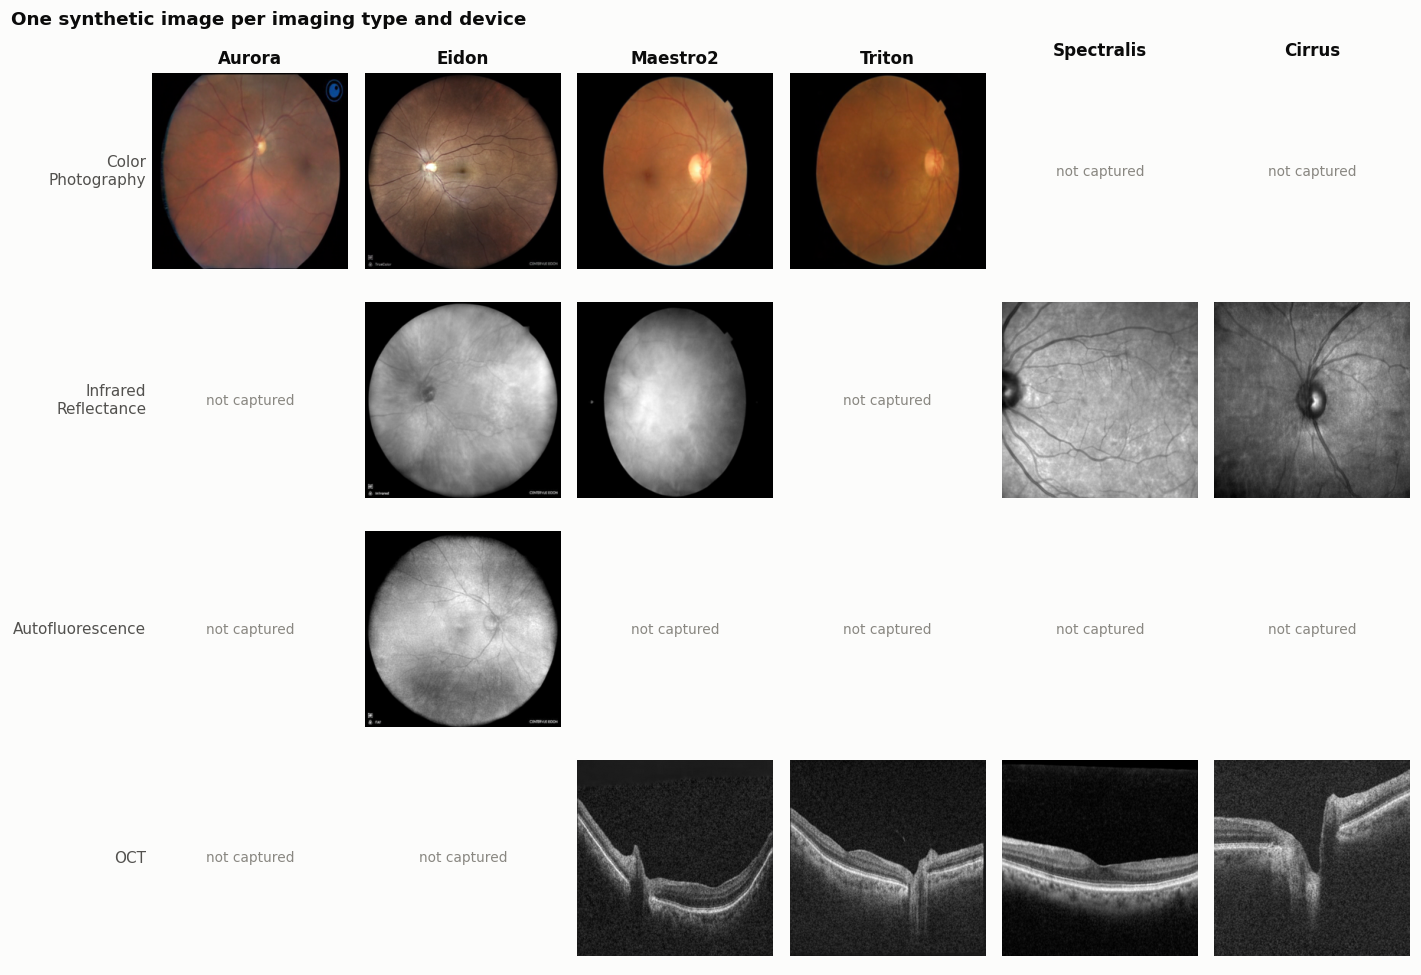

In [7]:
def read_pixels(path):
    return pydicom.dcmread(path).pixel_array

gallery = images.groupby(["imaging", "device"]).sample(1, random_state=SEED)
gallery["local"] = fetch_many(gallery.key)

fig, axes = plt.subplots(len(IMAGING), len(DEVICE_ORDER), figsize=(13, 9))
for i, imaging in enumerate(IMAGING):
    for j, device in enumerate(DEVICE_ORDER):
        ax = axes[i, j]
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for side in ax.spines.values():
            side.set_visible(False)
        row = gallery[(gallery.imaging == imaging) & (gallery.device == device)]
        if row.empty:
            ax.text(0.5, 0.5, "not captured", ha="center", va="center", color=MUTED, fontsize=9)
        else:
            px = read_pixels(row.local.iloc[0])
            if imaging in ("Infrared Reflectance", "Autofluorescence") and px.ndim == 3:
                px = px.mean(axis=2)
            ax.imshow(px, cmap=None if px.ndim == 3 else "gray")
        if i == 0:
            ax.set_title(device)
        if j == 0:
            ax.set_ylabel(imaging.replace(" ", "\n"), rotation=0, ha="right", va="center", color=INK2)
fig.suptitle("One synthetic image per imaging type and device", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

In [8]:
ds = pydicom.dcmread(gallery.local.iloc[0])
for tag in ["SOPClassUID", "Manufacturer", "ManufacturerModelName", "ImageLaterality",
            "Rows", "Columns", "SamplesPerPixel", "PhotometricInterpretation"]:
    value = ds.get(tag)
    print(f"{tag:28s} {getattr(value, 'name', value)}")

SOPClassUID                  Ophthalmic Photography 8 Bit Image Storage
Manufacturer                 iCare
ManufacturerModelName        Eidon
ImageLaterality              R
Rows                         256
Columns                      256
SamplesPerPixel              3
PhotometricInterpretation    RGB


In [9]:
def eye_labels(path):
    obs = pd.read_csv(path, index_col=0, low_memory=False)
    obs["label"] = obs.observation_source_value.str.split(",").str[0].str.replace("mhoccur_", "")
    return obs.pivot_table(index="person_id", columns="label", values="value_as_number")

fundus = fundus.join(eye_labels(paths["fundus/clinical_data/observation.csv"]), on="participant_id")
octs = octs.join(eye_labels(paths["oct/clinical_data/observation.csv"]), on="participant_id")
prevalence = pd.concat({
    "fundus photos": fundus.groupby("manufacturers_model_name")[["amd", "glc", "pdr"]].mean(),
    "OCT": octs.groupby("manufacturers_model_name")[["amd", "glc", "pdr"]].mean(),
}).mul(100).round(1)
prevalence.columns = ["AMD %", "glaucoma %", "diabetic retinopathy %"]
prevalence

AMD %  glaucoma %  \
              manufacturers_model_name                      
fundus photos Aurora                      5.5         8.2   
              Cirrus                      5.2         8.6   
              Eidon                       5.2         7.9   
              Maestro2                    5.3         8.2   
              Spectralis                  4.8         8.1   
              Triton                      5.1         8.1   
OCT           Cirrus                      5.6         8.3   
              Maestro2                    5.4         8.4   
              Spectralis                  5.4         8.4   
              Triton                      5.2         8.3   

                                        diabetic retinopathy %  
              manufacturers_model_name                          
fundus photos Aurora                                       4.2  
              Cirrus                                       4.6  
              Eidon                                        4.4  
              Maestro2                                     4.2  
              Spectralis                                   4.2  
              Triton                                       4.3  
OCT           Cirrus                                       4.5  
              Maestro2                                     4.3  
              Spectralis                                   4.6  
              Triton                                       4.4

### 3.2 ECG: machine measurements for every participant

Each participant has a 12-lead WFDB record (`.hea` header plus `.dat` samples) from a Philips PageWriter TC30.
In this synthetic release the **waveform samples are flat placeholders**: we checked 301 records and every lead
sits at 0 mV. The synthetic content is in the machine measurements (heart rate, PR, QRS, QT, QTc) and the
device's text interpretation, which appear in each header and in `manifest.tsv`.

participant 7: 12 leads (I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6), 500 Hz, 11 s
  device_model               PageWriter TC30
  interpretation_comment_2   - ABNORMAL -
  comment_1_val              Normal sinus rhythm at 56.362297 bpm
  comment_2_val              PR interval within normal limits (192.93842 ms)
  comment_3_val              QRS duration is normal (78.99686 ms)
  comment_4_val              QTc is 430.02734 ms, which is within normal range
waveform range across all 12 leads: 0.00 mV


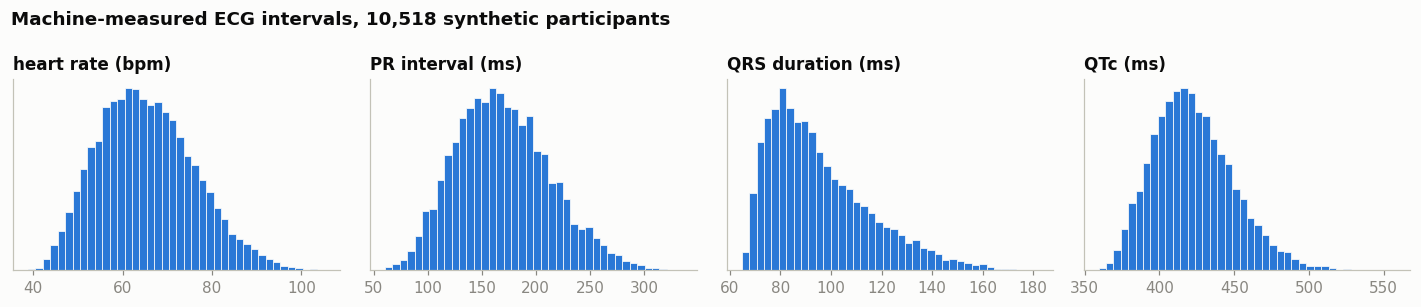

In [10]:
ecg = pd.read_csv(paths["tabular/cardiac_ecg/manifest.tsv"], sep="\t", index_col=0).set_index("participant_id")

pid = 7
for ext in ("hea", "dat"):
    fetch(f"{ROOT}/tabular/cardiac_ecg/{pid}/{pid}_ecg_synthetic.{ext}")
rec = wfdb.rdrecord(str(CACHE / ROOT / "tabular/cardiac_ecg" / str(pid) / f"{pid}_ecg_synthetic"))
header = dict(line.split(": ", 1) for line in rec.comments if ": " in line)

print(f"participant {pid}: {rec.n_sig} leads ({', '.join(rec.sig_name)}), {rec.fs} Hz, {rec.sig_len / rec.fs:.0f} s")
for key in ["device_model", "interpretation_comment_2", "comment_1_val", "comment_2_val", "comment_3_val", "comment_4_val"]:
    print(f"  {key:26s} {header.get(key)}")
print(f"waveform range across all 12 leads: {np.ptp(rec.p_signal):.2f} mV")

INTERVALS = {"Rate": "heart rate (bpm)", "PR": "PR interval (ms)", "QRSD": "QRS duration (ms)", "QTc": "QTc (ms)"}
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, (col, label) in zip(axes, INTERVALS.items()):
    ax.hist(ecg[col], bins=40, color=SLOTS[0], edgecolor=SURFACE, linewidth=0.5)
    ax.set_title(label, loc="left")
    ax.set_yticks([])
    ax.grid(False)
fig.suptitle(f"Machine-measured ECG intervals, {len(ecg):,} synthetic participants", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

### 3.3 Wearable and CGM summaries, clinical labs and conditions

The real AI-READI release has 10 days of Dexcom glucose at 5 minute resolution and Garmin streams. The synthetic
release condenses these into **summary features, one row per participant**. The units are not documented inside
the file, so treat them as relative measures.

In [11]:
wear = pd.read_csv(paths["tabular/synthetic_wearable_activity_glucose.tsv"], sep="\t", index_col=0).set_index("participant_id")

meas = pd.read_csv(paths["tabular/clinical_data/measurement.csv"], index_col=0, low_memory=False)
meas["var"] = meas.measurement_source_value.str.split(",").str[0]
labs = meas.pivot_table(index="person_id", columns="var", values="value_as_number")

cond = pd.read_csv(paths["tabular/clinical_data/condition_occurrence.csv"], index_col=0, low_memory=False)
cond["var"] = cond.condition_source_value.str.split(",").str[0]
cond_names = (cond.groupby("var").condition_source_value.first().str.split(",", n=1).str[1]
              .str.replace(r"\s*\((Examples|elevated)[^)]*\)?$|\s*\([^)]*$", "", regex=True).str.strip())
dx = pd.crosstab(cond.person_id, cond["var"]).clip(upper=1).reindex(labs.index, fill_value=0)

print(f"wearable/CGM: {wear.shape[0]:,} participants x {wear.shape[1]} features")
print(f"labs and vitals: {labs.shape[0]:,} participants x {labs.shape[1]} measures (OMOP measurement)")
print(f"conditions: {dx.shape[1]} self-reported conditions (OMOP condition_occurrence)")
wear.describe().T[["mean", "std", "min", "max"]].round(1)

wearable/CGM: 10,518 participants x 16 features
labs and vitals: 10,518 participants x 73 measures (OMOP measurement)
conditions: 30 self-reported conditions (OMOP condition_occurrence)


,mean,std,min,max
heart_rate_mean,75.0,9.7,48.7,104.3
blood_glucose_mean,140.0,35.5,59.3,270.9
resp_rate_mean,14.6,1.3,12.3,19.7
stress_mean,57.3,18.6,11.5,96.5
blood_glucose_std,25.4,16.5,4.6,98.8
total_steps,808.3,570.6,21.0,3840.9
resting_heart_rate,75.0,9.7,49.0,105.5
total_kcal,17.8,41.7,0.0,566.0
sleep_light_hrs,0.3,0.2,0.0,1.1
sleep_deep_hrs,0.1,0.1,0.0,0.7


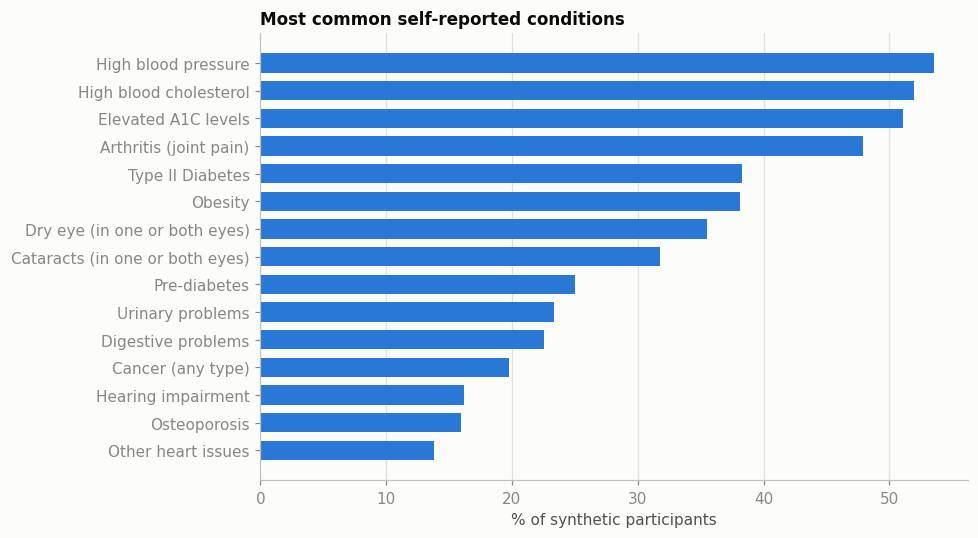

In [12]:
top = dx.mean().mul(100).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([cond_names.get(v, v) for v in top.index], top.values, color=SLOTS[0], height=0.7)
ax.set_xlabel("% of synthetic participants")
ax.grid(axis="y", visible=False)
ax.set_title("Most common self-reported conditions", loc="left")
plt.tight_layout()

## 4. Relationships across data types

Inside the tabular cohort every participant has labs, conditions, an ECG and wearable/CGM features. If the
generator learned the real joint distribution, physiology we already know should show up **across** these files.
That is also a quick way to judge how far to trust a synthetic dataset.

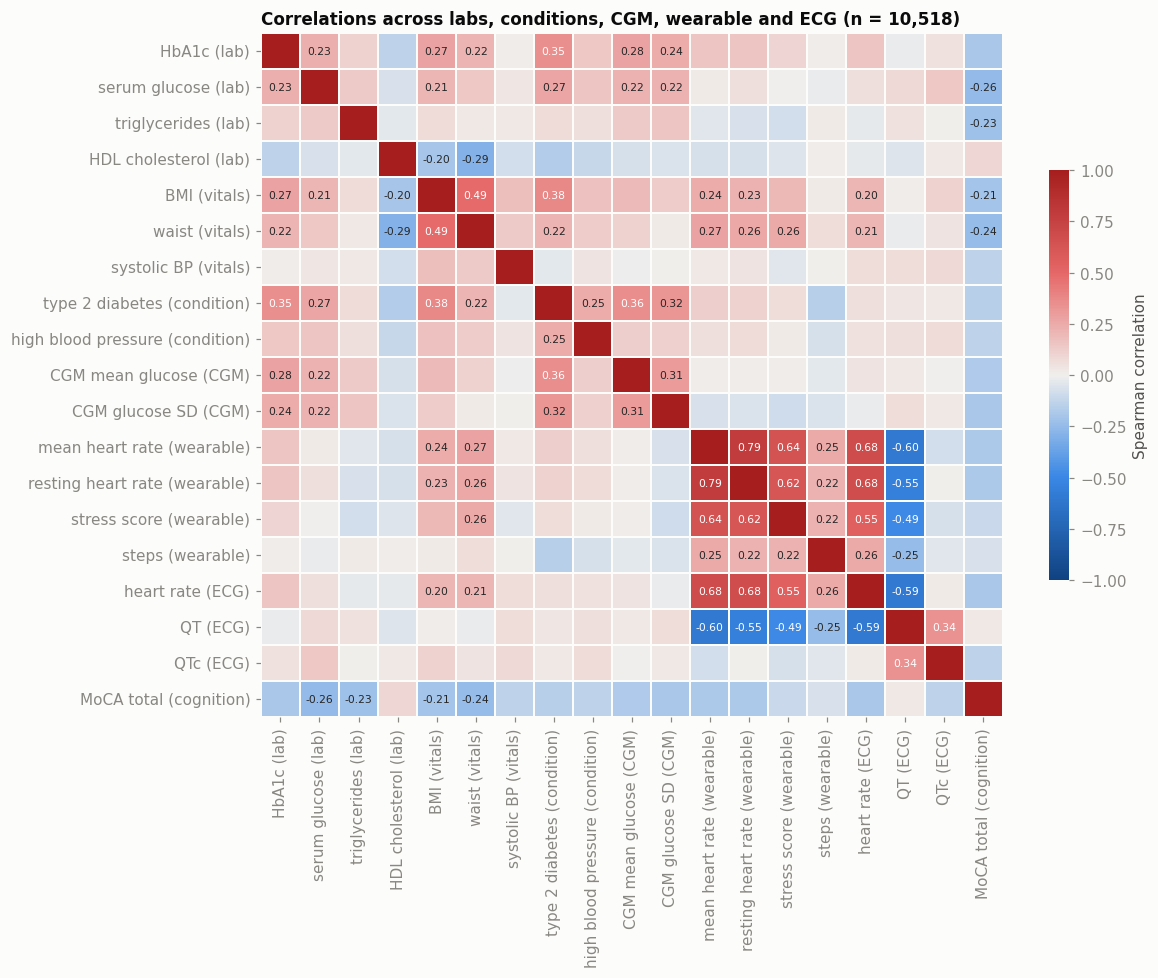

In [13]:
cohort = (labs.join(dx)
              .join(wear.add_prefix("wear_"))
              .join(ecg[["Rate", "PR", "QRSD", "QT", "QTc"]].add_prefix("ecg_")))

VARS = {  # column: (label, source)
    "import_hba1c": ("HbA1c", "lab"), "import_glucose": ("serum glucose", "lab"),
    "import_triglycerides": ("triglycerides", "lab"), "import_hdl_cholesterol": ("HDL cholesterol", "lab"),
    "bmi_vsorres": ("BMI", "vitals"), "waist_vsorres": ("waist", "vitals"), "bp1_sysbp_vsorres": ("systolic BP", "vitals"),
    "mhterm_dm2": ("type 2 diabetes", "condition"), "mhoccur_hbp": ("high blood pressure", "condition"),
    "wear_blood_glucose_mean": ("CGM mean glucose", "CGM"), "wear_blood_glucose_std": ("CGM glucose SD", "CGM"),
    "wear_heart_rate_mean": ("mean heart rate", "wearable"), "wear_resting_heart_rate": ("resting heart rate", "wearable"),
    "wear_stress_mean": ("stress score", "wearable"), "wear_total_steps": ("steps", "wearable"),
    "ecg_Rate": ("heart rate", "ECG"), "ecg_QT": ("QT", "ECG"), "ecg_QTc": ("QTc", "ECG"),
    "moca_total_score": ("MoCA total", "cognition"),
}
corr = cohort[list(VARS)].corr(method="spearman")
names = [f"{label} ({src})" for label, src in VARS.values()]

diverging = sns.blend_palette(["#104281", "#3987e5", "#f0efec", "#e66767", "#a61e1e"], as_cmap=True)
annot = corr.map(lambda r: f"{r:.2f}" if abs(r) >= 0.2 and abs(r) < 0.999 else "")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap=diverging, vmin=-1, vmax=1, center=0, annot=annot, fmt="", annot_kws={"size": 7},
            xticklabels=names, yticklabels=names, linewidths=1, linecolor=SURFACE,
            cbar_kws={"label": "Spearman correlation", "shrink": 0.6}, ax=ax)
ax.grid(False)
ax.set_title(f"Correlations across labs, conditions, CGM, wearable and ECG (n = {len(cohort):,})", loc="left")
plt.tight_layout()

In [14]:
checks = [  # (x, y, what physiology predicts)
    ("ecg_Rate", "wear_heart_rate_mean", "strong positive"),
    ("ecg_QT", "ecg_Rate", "strong negative"),
    ("import_hba1c", "wear_blood_glucose_mean", "positive"),
    ("import_hba1c", "mhterm_dm2", "positive"),
    ("bmi_vsorres", "waist_vsorres", "strong positive"),
    ("bp1_sysbp_vsorres", "mhoccur_hbp", "positive"),
    ("wear_total_steps", "bmi_vsorres", "negative"),
    ("import_creatinine", "mhoccur_rnl", "positive"),
]
pd.DataFrame([{
    "pair": f"{a}  vs  {b}", "expected": e,
    "spearman r": round(cohort[a].corr(cohort[b], method="spearman"), 2)} for a, b, e in checks
]).set_index("pair")

,expected,spearman r
pair,,
ecg_Rate vs wear_heart_rate_mean,strong positive,0.68
ecg_QT vs ecg_Rate,strong negative,-0.59
import_hba1c vs wear_blood_glucose_mean,positive,0.28
import_hba1c vs mhterm_dm2,positive,0.35
bmi_vsorres vs waist_vsorres,strong positive,0.49
bp1_sysbp_vsorres vs mhoccur_hbp,positive,0.05
wear_total_steps vs bmi_vsorres,negative,0.02
import_creatinine vs mhoccur_rnl,positive,0.07


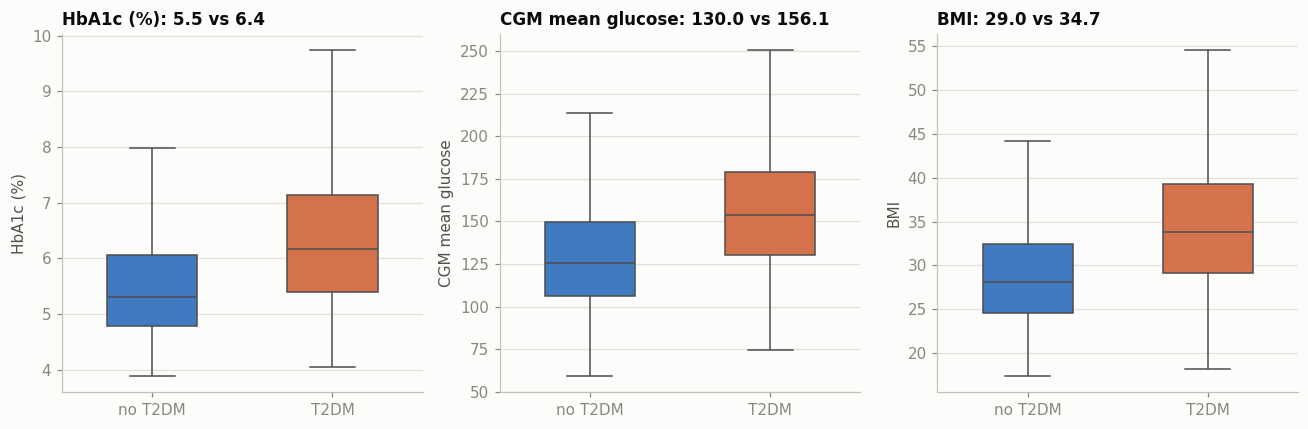

In [15]:
t2d = cohort.assign(group=cohort.mhterm_dm2.map({0: "no T2DM", 1: "T2DM"}))
panels = [("import_hba1c", "HbA1c (%)"), ("wear_blood_glucose_mean", "CGM mean glucose"), ("bmi_vsorres", "BMI")]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (col, label) in zip(axes, panels):
    sns.boxplot(data=t2d, x="group", y=col, hue="group", order=["no T2DM", "T2DM"],
                palette={"no T2DM": SLOTS[0], "T2DM": SLOTS[1]}, showfliers=False, width=0.5, ax=ax, legend=False)
    means = t2d.groupby("group")[col].mean()
    ax.set_title(f"{label}: {means['no T2DM']:.1f} vs {means['T2DM']:.1f}", loc="left")
    ax.set_xlabel(""); ax.set_ylabel(label)
plt.tight_layout()

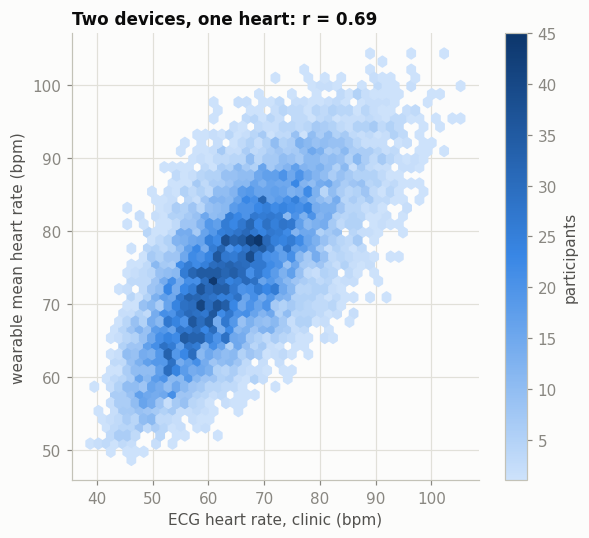

In [16]:
fig, ax = plt.subplots(figsize=(5.5, 5))
hb = ax.hexbin(cohort.ecg_Rate, cohort.wear_heart_rate_mean, gridsize=45, mincnt=1,
               cmap=sns.blend_palette(["#cde2fb", "#3987e5", "#0d366b"], as_cmap=True))
r = cohort.ecg_Rate.corr(cohort.wear_heart_rate_mean)
ax.set_xlabel("ECG heart rate, clinic (bpm)")
ax.set_ylabel("wearable mean heart rate (bpm)")
ax.set_title(f"Two devices, one heart: r = {r:.2f}", loc="left")
fig.colorbar(hb, ax=ax, label="participants")
plt.tight_layout()

## 5. Challenge: which device took this scan?

Every imaging device leaves a fingerprint: optics, sensor noise, compression, post-processing. In a famous chest
X-ray study, a network could tell *which hospital* an image came from almost perfectly
([Zech et al., PLOS Medicine 2018](https://doi.org/10.1371/journal.pmed.1002683)). Fingerprints like this are how
models learn shortcuts and why a model trained on one OCT device often underperforms on another.

Last year's AI-READI demo showed that a classifier can name the device from grayscale random pieces of retinal
images that people cannot tell apart. We repeat it here on **synthetic** OCT, which asks an extra question:
**did the diffusion model learn each device's fingerprint too?**

We make the task harder step by step:

| Level | What the model sees |
|---|---|
| `whole` | the full B-scan, shrunk to 64 x 64 pixels |
| `crop64` | a random 64 x 64 piece at full resolution |
| `crop64n` | the same piece with brightness and contrast removed |
| `crop32n` | a random 32 x 32 piece, brightness and contrast removed |

Four devices, so guessing gets 25%.

In [17]:
MODALITY = "OCT"        # try "Color Photography" or "Infrared Reflectance" afterwards
N_PER_DEVICE = 1000     # images per device; 1,000 is about 65 MB for OCT

pool = images[images.imaging == MODALITY]
subset = pool.groupby("device").sample(N_PER_DEVICE, random_state=SEED).reset_index(drop=True)
t0 = time.time()
subset["local"] = fetch_many(subset.key)

def load_gray(path):
    px = read_pixels(path)
    if px.ndim == 3:  # RGB photo: convert to grayscale, as in the original demo
        px = px[..., :3].astype(np.float32) @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    return px.astype(np.uint8)

with ThreadPoolExecutor(16) as pool_:
    X = np.stack(list(pool_.map(load_gray, subset.local)))
DEVICES = sorted(subset.device.unique())
y = subset.device.map({d: i for i, d in enumerate(DEVICES)}).to_numpy()
print(f"{len(X):,} {MODALITY} images {X.shape[1:]} from {DEVICES} in {time.time() - t0:.0f} s")

4,000 OCT images (256, 256) from ['Cirrus', 'Maestro2', 'Spectralis', 'Triton'] in 38 s


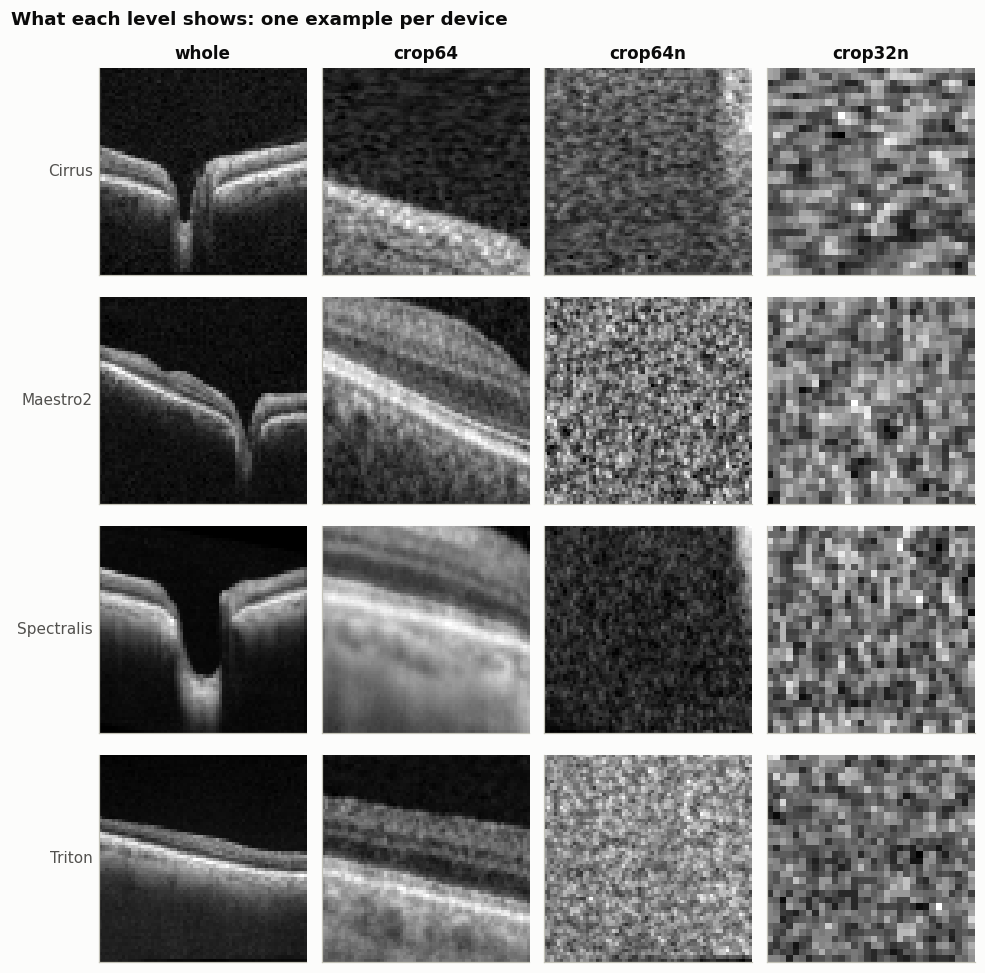

In [18]:
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.model_selection import train_test_split

DEV = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(os.cpu_count())
Xt = torch.from_numpy(X)                                 # uint8; converted to float per batch to save memory
train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=SEED)
LEVELS = ["whole", "crop64", "crop64n", "crop32n"]

def make_view(idx, level, seed):
    # One batch of model inputs for a difficulty level.
    g = torch.Generator().manual_seed(seed)
    batch = Xt[idx]
    if level == "whole":                                  # full scan, 256 -> 64 pixels
        return torch.cat([F.avg_pool2d(c[:, None].float() / 255, 4) for c in batch.split(500)])
    size = 32 if level == "crop32n" else 64
    top = torch.randint(0, 257 - size, (len(idx),), generator=g)
    left = torch.randint(0, 257 - size, (len(idx),), generator=g)
    crops = torch.stack([im[t:t + size, l:l + size] for im, t, l in zip(batch, top, left)])[:, None].float() / 255
    if level.endswith("n"):                              # remove brightness and contrast cues
        crops = (crops - crops.mean((2, 3), keepdim=True)) / (crops.std((2, 3), keepdim=True) + 1e-6)
    return crops

fig, axes = plt.subplots(len(DEVICES), len(LEVELS), figsize=(9, 9))
example = [int(train_idx[y[train_idx] == k][0]) for k in range(len(DEVICES))]
for i, idx in enumerate(example):
    for j, level in enumerate(LEVELS):
        ax = axes[i, j]
        ax.imshow(make_view([idx], level, seed=j)[0, 0], cmap="gray")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if i == 0: ax.set_title(level)
        if j == 0: ax.set_ylabel(DEVICES[i], rotation=0, ha="right", va="center")
plt.suptitle("What each level shows: one example per device", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

### 5.1 Your turn

Below are 12 contrast-normalized 64 x 64 crops (level `crop64n`) from scans held out of training. Study the
labeled row first, then write down a device letter for each numbered crop.

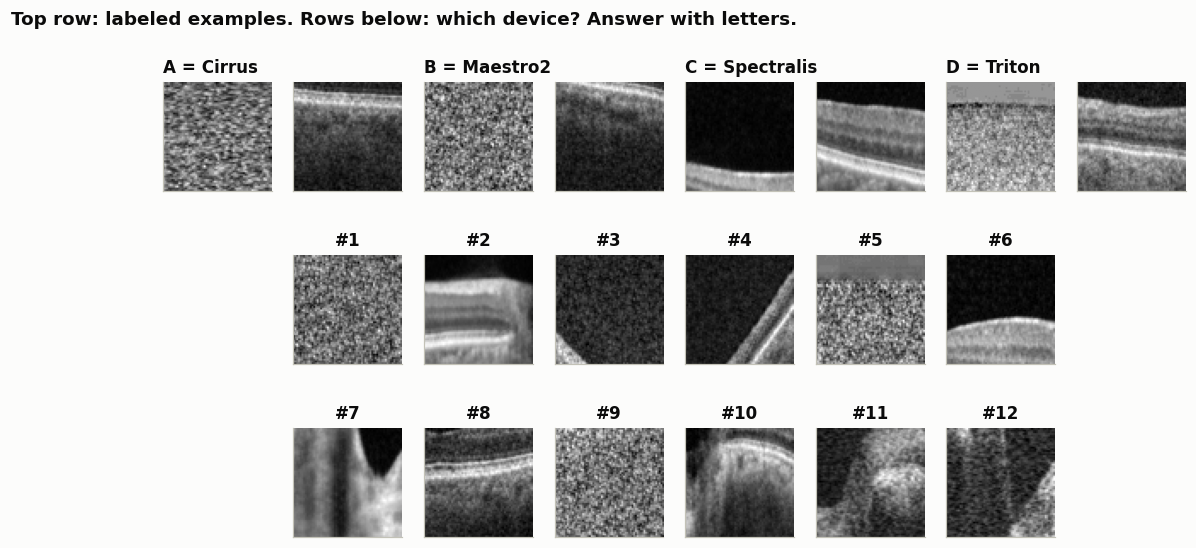

In [19]:
LETTERS = {d: chr(65 + i) for i, d in enumerate(DEVICES)}
rng = np.random.default_rng(2026)
quiz_idx = rng.permutation(np.concatenate(
    [rng.choice(test_idx[y[test_idx] == k], 3, replace=False) for k in range(len(DEVICES))]))
quiz_views = make_view(quiz_idx, "crop64n", seed=2026)

fig = plt.figure(figsize=(12, 5.6))
grid = fig.add_gridspec(3, 8, hspace=0.35)
for k, d in enumerate(DEVICES):                          # labeled study examples: two per device
    for s in range(2):
        ax = fig.add_subplot(grid[0, 2 * k + s])
        idx = int(train_idx[y[train_idx] == k][10 + s])
        ax.imshow(make_view([idx], "crop64n", seed=s)[0, 0], cmap="gray")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if s == 0: ax.set_title(f"{LETTERS[d]} = {d}", loc="left")
for q in range(12):                                     # the quiz
    ax = fig.add_subplot(grid[1 + q // 6, (q % 6) + 1])
    ax.imshow(quiz_views[q, 0], cmap="gray")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"#{q + 1}")
fig.suptitle("Top row: labeled examples. Rows below: which device? Answer with letters.",
             x=0.01, ha="left", fontweight="bold")
plt.show()

In [20]:
MY_GUESSES = ""   # e.g. "ABDCCABDAACB", one letter per numbered crop
print(f"{len(MY_GUESSES.strip())} of 12 answers entered")

0 of 12 answers entered


### 5.2 Now the model

A four-layer convolutional network, trained from scratch on each level with fresh random crops every epoch. On a
GPU the four levels take under a minute; on a CPU-only VM, a few minutes.

In [21]:
EPOCHS = 12 if DEV == "cuda" else 6

def small_cnn(n_classes):
    layers, ch = [], [1, 32, 64, 128]
    for a, b in zip(ch[:-1], ch[1:]):
        layers += [nn.Conv2d(a, b, 3, padding=1), nn.BatchNorm2d(b), nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, n_classes))

def train_level(level, epochs=EPOCHS, batch=128):
    torch.manual_seed(SEED)
    model = small_cnn(len(DEVICES)).to(DEV)
    steps = epochs * ((len(train_idx) + batch - 1) // batch)
    opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=4e-3, total_steps=steps)
    targets = torch.from_numpy(y[train_idx])
    for epoch in range(epochs):
        model.train()
        views = make_view(train_idx, level, seed=epoch)  # new random crops every epoch
        for b in torch.randperm(len(train_idx)).split(batch):
            if len(b) < 2:                               # BatchNorm needs at least two samples
                continue
            loss = F.cross_entropy(model(views[b].to(DEV)), targets[b].to(DEV))
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return model

@torch.no_grad()
def predict(model, views):
    model.eval()
    return torch.cat([model(v.to(DEV)).argmax(1).cpu() for v in views.split(512)]).numpy()

models, accuracy = {}, {}
for level in LEVELS:
    t0 = time.time()
    models[level] = train_level(level)
    pred = predict(models[level], make_view(test_idx, level, seed=999))
    accuracy[level] = (pred == y[test_idx]).mean()
    print(f"{level:8s} test accuracy {accuracy[level]:.1%}   ({time.time() - t0:.0f} s on {DEV})")

whole    test accuracy 99.2%   (10 s on cuda)


crop64   test accuracy 91.2%   (4 s on cuda)


crop64n  test accuracy 89.0%   (5 s on cuda)


crop32n  test accuracy 79.9%   (4 s on cuda)


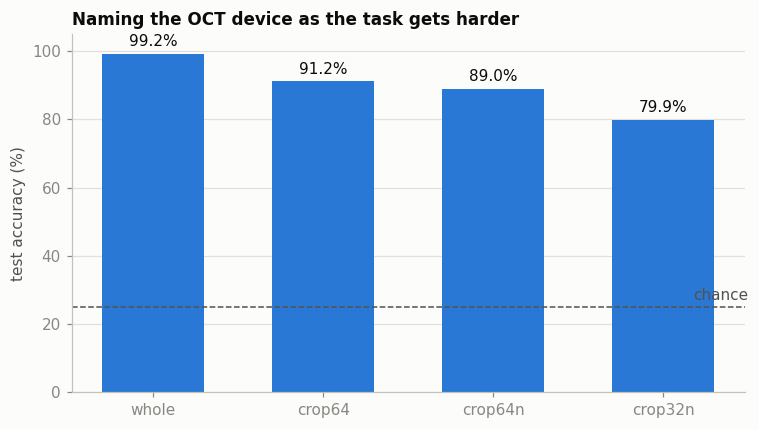

In [22]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(LEVELS, [accuracy[l] * 100 for l in LEVELS], color=SLOTS[0], width=0.6)
ax.bar_label(bars, labels=[f"{accuracy[l]:.1%}" for l in LEVELS], padding=3, color=INK)
ax.axhline(100 / len(DEVICES), color=INK2, linestyle="--", linewidth=1)
ax.text(len(LEVELS) - 0.5, 100 / len(DEVICES) + 2, "chance", ha="right", color=INK2)
ax.set_ylim(0, 105); ax.set_ylabel("test accuracy (%)"); ax.grid(axis="x", visible=False)
ax.set_title(f"Naming the {MODALITY} device as the task gets harder", loc="left")
plt.tight_layout()

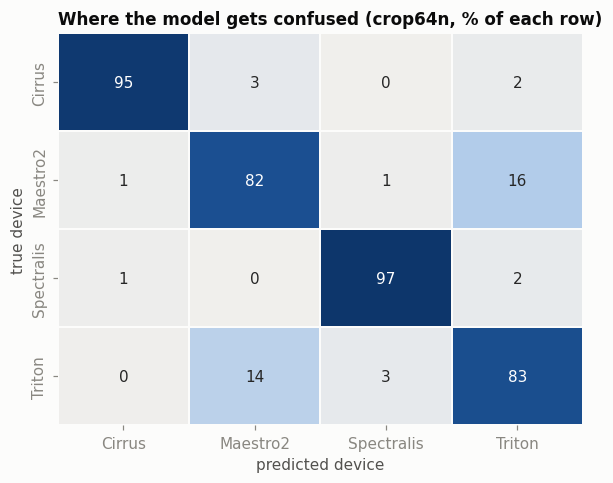

In [23]:
from sklearn.metrics import confusion_matrix
level = "crop64n"
pred = predict(models[level], make_view(test_idx, level, seed=999))
cm = confusion_matrix(y[test_idx], pred, normalize="true") * 100
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt=".0f", cmap=sns.blend_palette(["#f0efec", "#3987e5", "#0d366b"], as_cmap=True),
            xticklabels=DEVICES, yticklabels=DEVICES, cbar=False, linewidths=1, linecolor=SURFACE, ax=ax)
ax.grid(False)
ax.set_xlabel("predicted device"); ax.set_ylabel("true device")
ax.set_title(f"Where the model gets confused ({level}, % of each row)", loc="left")
plt.tight_layout()

### 5.3 The reveal

In [24]:
quiz_pred = predict(models["crop64n"], quiz_views)
answer = pd.DataFrame({
    "crop": [f"#{q + 1}" for q in range(12)],
    "true device": [f"{LETTERS[DEVICES[k]]} {DEVICES[k]}" for k in y[quiz_idx]],
    "model": [f"{LETTERS[DEVICES[k]]} {DEVICES[k]}" for k in quiz_pred],
}).set_index("crop")
answer["you"] = list(MY_GUESSES.upper().ljust(12, "-"))[:12]
model_score = (quiz_pred == y[quiz_idx]).sum()
your_score = sum(g == t[0] for g, t in zip(answer["you"], answer["true device"]))
print(f"model: {model_score}/12   you: {your_score}/12   chance: 3/12")
answer

model: 10/12   you: 0/12   chance: 3/12


,true device,model,you
crop,,,
#1,B Maestro2,B Maestro2,-
#2,C Spectralis,C Spectralis,-
#3,D Triton,B Maestro2,-
#4,D Triton,D Triton,-
#5,B Maestro2,B Maestro2,-
#6,C Spectralis,C Spectralis,-
#7,C Spectralis,C Spectralis,-
#8,A Cirrus,A Cirrus,-
#9,B Maestro2,B Maestro2,-


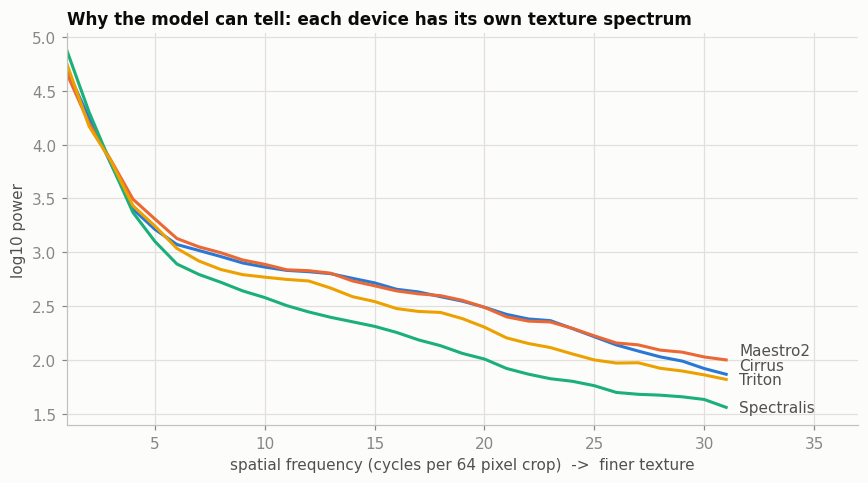

In [25]:
def radial_spectrum(views):
    # Average power at each spatial frequency, over a batch of normalized crops.
    n = views.shape[-1]
    win = torch.hann_window(n)[:, None] * torch.hann_window(n)[None, :]
    power = torch.fft.fftshift(torch.fft.fft2(views[:, 0] * win), dim=(-2, -1)).abs().pow(2).mean(0)
    yy, xx = torch.meshgrid(torch.arange(n) - n // 2, torch.arange(n) - n // 2, indexing="ij")
    radius = (yy ** 2 + xx ** 2).sqrt().round().long().ravel()
    sums = torch.zeros(radius.max() + 1).index_add_(0, radius, power.ravel())
    return (sums / torch.bincount(radius))[1: n // 2].numpy()

fig, ax = plt.subplots(figsize=(8, 4.5))
freqs = np.arange(1, 32)
spectra = {d: np.log10(radial_spectrum(make_view(test_idx[y[test_idx] == k], "crop64n", seed=7)))
           for k, d in enumerate(DEVICES)}
span = max(s.max() for s in spectra.values()) - min(s.min() for s in spectra.values())
label_y, gap = {}, 0.04 * span                           # direct labels, nudged apart so they never overlap
for d in sorted(spectra, key=lambda d: spectra[d][-1]):
    label_y[d] = max(spectra[d][-1], max(label_y.values(), default=-np.inf) + gap)
for k, d in enumerate(DEVICES):
    ax.plot(freqs, spectra[d], color=SLOTS[k])
    ax.text(freqs[-1] + 0.6, label_y[d], d, color=INK2, va="center")
ax.set_xlim(1, 37)
ax.set_xlabel("spatial frequency (cycles per 64 pixel crop)  ->  finer texture")
ax.set_ylabel("log10 power")
ax.set_title("Why the model can tell: each device has its own texture spectrum", loc="left")
plt.tight_layout()

## 6. Problems worth a grant

Each idea below can be prototyped on the synthetic data today and then run on the real AI-READI release.

**1. Device-invariant retinal biomarkers.** Part 5 shows how easily the device leaks into a model. Build
representations that predict disease but *cannot* predict the device, and use the device classifier from this
notebook as the leakage test. AI-READI is one of the few datasets where the same eyes are imaged on several
machines, which makes this testable. (Related: the MICCAI 2026 DA-OCT cross-vendor OCT challenge on AI-READI.)

**2. The retina as a window on metabolic health.** On the real data, images and labs belong to the same people:
predict HbA1c, kidney function or diabetes severity group from retinal photos and OCT, and ask whether the retina
shows who is moving toward health. Build and debug the pipeline on synthetic data now.

**3. Glucose dynamics in daily life.** Link CGM variability to sleep, stress, activity and air quality at home.
The real release has 10 days of 5 minute CGM plus Garmin and environmental streams on the same people; the
synthetic summaries already show glycemic signals lining up with HbA1c and diagnosis.

**4. Pathways toward health (salutogenesis).** The four severity groups from no diabetes to insulin form a
spectrum. Model where individuals sit on it across eyes, heart, glucose and cognition, and which factors mark
the people doing better than their group.

**5. How faithful is synthetic multimodal data?** Part 4 found that strong relationships survived synthesis
and several weaker ones did not. A systematic fidelity and privacy scorecard for multimodal synthetic health
data, validated against the real AI-READI release, would help every Bridge2AI dataset.

## 7. Next steps and resources

* **Real AI-READI data:** documentation at [docs.aireadi.org](https://docs.aireadi.org/), access through
  [FAIRhub](https://fairhub.io/) under a data license agreement.
* **This synthetic dataset:** AWS Marketplace listing *ADVANCE Center Synthetic AI-READI Dataset for T2DM Research*;
  archive and license on [Zenodo (doi:10.5281/zenodo.22944362)](https://doi.org/10.5281/zenodo.22944362); generation
  code at [github.com/nicholas-j-jackson/ai_readi_synth](https://github.com/nicholas-j-jackson/ai_readi_synth).
* **Citing AI-READI:** AI-READI Consortium, *Nature Metabolism* 2024,
  [doi:10.1038/s42255-024-01165-x](https://doi.org/10.1038/s42255-024-01165-x); study protocol, *BMJ Open* 2025,
  [doi:10.1136/bmjopen-2024-097449](https://doi.org/10.1136/bmjopen-2024-097449).
* **Device fingerprints and shortcut learning:** Zech et al., *PLOS Medicine* 2018,
  [doi:10.1371/journal.pmed.1002683](https://doi.org/10.1371/journal.pmed.1002683).

Try it yourself: change `MODALITY` in Part 5 to `"Color Photography"` or `"Infrared Reflectance"`, or swap the
variables in Part 4 for your own hypothesis.